# 05 — 적합도 예측 신뢰도 보정 (`results/calib_logistic`)

회귀 모델이 내는 예측 평균 $\mu$ · 가지 간 표준편차 $\sigma$ 로부터 예측마다 신뢰도 2종을 확률로 계산하는 로지스틱 함수를 만든다. 보정 자료는 서비스 회귀 모델과 같은 입력 조합(`noseq`)의 **교차검증 예측** 이다. 각 예측은 그 유전자의 genus 를 학습에 쓰지 않은 모델이 낸 값이라, 새 균주를 예측할 때의 오차 양상을 담는다.

| 신뢰도 | 정의 | 범위 |
|---|---|---|
| `conf_sign` | 실제 적합도가 예측 쪽(균주 평균보다 높음 / 낮음)에 있을 확률 — 방향 신뢰도 | 0.5 ~ 1 |
| `conf_fit` | 실제 적합도가 $\mu \pm \delta$ 안에 있을 확률 — 허용 오차 확률 ($\delta$ = 0.5, 균주 내 z 단위) | 0 ~ 1 |

| 파일 (`results/calib_logistic/`) | 내용 |
|---|---|
| `calibration.json` | 두 로지스틱 함수의 계수 · $\delta$ · 학습 조건 (서비스 `assets/` 에 그대로 복사해 쓴다) |
| `check_conf_sign.csv` · `check_conf_fit.csv` | genus 단위 검증 — 예측 확률 구간별 실제 비율 |
| `calibration.png` | 같은 검증의 보정 그림 |

진행: 1 데이터 → 2 설계 변수 → 3 방향 신뢰도 → 4 허용 오차 확률 → 5 genus 단위 검증 → 6 최종 계수

In [1]:
import os, json, glob
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from scipy.special import expit
from scipy.stats import norm
from proteomefit import data
from proteomefit.config import Config

cfg     = Config()                                   # base data 경로
CV_DIR  = '../results/fitpred_ablation/noseq'         # 서비스 회귀 모델과 같은 입력 조합의 교차검증 결과
OUT_DIR = '../results/calib_logistic'
DELTA   = 0.5                                         # conf_fit 허용 오차 (균주 내 z 단위)
SE_MAX  = 0.25                                        # conf_fit 학습에 쓰는 라벨 측정 오차 상한 (z 단위)
BINS    = [0, .3, .5, .6, .7, .8, .9, 1.01]           # 검증 표의 확률 구간
os.makedirs(OUT_DIR, exist_ok=True)

## 1. 데이터 — 교차검증 예측과 라벨

| 기호 | 형태 | 내용 |
|---|---|---|
| $\mu$ · $\sigma$ | `[n_pred]` | `CV_DIR/fold##_<genus>/inner##/pred.npz` 의 `mu` · `sd` (28 외부 폴드 x 내부 폴드 3개, 시험 genus 샘플 순서) |
| $y$ | `[n_pred]` | 균주 내 z-정규화 `fit_mean` (회귀 라벨과 같다) |
| $se$ | `[n_pred]` | 라벨 측정 오차 = `comb_se` / 균주별 `fit_mean` 표준편차 (z 단위) |

$$y_i = \frac{f_i - \bar{f}_{o(i)}}{s_{o(i)}}, \qquad se_i = \frac{\mathrm{comb\_se}_i}{s_{o(i)}}$$

- $f_i$ — 원본 `fit_mean`, $\bar{f}_o$ · $s_o$ — 균주 $o$ 의 `fit_mean` 평균 · 표준편차
- 예: $s_o = 0.8$, `comb_se` = 0.2 → $se = 0.25$. 측정 오차가 라벨 단위로 0.25 라는 뜻이다
- 같은 유전자가 내부 폴드 3개에서 한 번씩 예측되므로 예측 수는 유전자 수의 3배다

In [2]:
# 라벨 - 적합도 수치가 있는 샘플 (회귀 학습 샘플과 같은 순서) [n]
D      = data.load_samples(cfg.base_dir, cfg.label_col, finite_only=True)
se_all = data.load_basedata(cfg.base_dir, usecols=['comb_se']).comb_se.to_numpy(float)   # [n_all]
fit    = D.yb[D.keep]                                          # 원본 적합도 [n]
g      = pd.Series(fit).groupby(D.org)
sd_org = g.transform('std').to_numpy()                         # 균주별 fit_mean 표준편차 [n]
y      = ((fit - g.transform('mean')) / sd_org).to_numpy()     # 라벨 (균주 내 z) [n]
se     = se_all[D.keep] / sd_org                               # 라벨 측정 오차 (z 단위) [n]

# 교차검증 예측 [n_pred, 5]
rows = []
for d in sorted(glob.glob(f'{CV_DIR}/fold*')):
    genus = os.path.basename(d).split('_', 1)[1]
    te    = np.flatnonzero(D.gen == genus)                     # 시험 샘플 (pred.npz 와 같은 순서)
    for f in sorted(glob.glob(f'{d}/inner*/pred.npz')):
        z = np.load(f)
        rows.append(pd.DataFrame({'mu': z['mu'], 'sd': z['sd'], 'y': y[te], 'se': se[te], 'genus': genus}))
R = pd.concat(rows, ignore_index=True)
print(f'cross-validation predictions: {len(R):,} | genera {R.genus.nunique()} | genes {len(y):,}')
print(f'label se (z): median {R.se.median():.3f} | share se <= {SE_MAX}: {(R.se <= SE_MAX).mean():.1%}')
print(f'mu: median |mu| {R.mu.abs().median():.3f} | sd: median {R.sd.median():.3f}')

cross-validation predictions: 531,951 | genera 28 | genes 177,317
label se (z): median 0.472 | share se <= 0.25: 11.0%
mu: median |mu| 0.456 | sd: median 0.530


## 2. 설계 변수

$$\mathbf{x} = \big(1,\ L,\ S,\ L S\big), \qquad L = \log(\lvert\mu\rvert + 0.05), \qquad S = \log\sigma$$

- $L$ — 예측 효과 크기. 0.05 를 더해 $\mu = 0$ 에서도 유한하다
- $S$ — 예측 불확실도. 미니 MLP 가지들이 서로 얼마나 다르게 예측했는가
- $L S$ — 두 항의 곱 (`conf_sign` 만). 같은 $\sigma$ 라도 $\lvert\mu\rvert$ 에 따라 효과가 달라지는 것을 담는다
- 예: $\mu = -1.0,\ \sigma = 0.5$ → $L = \log 1.05 = 0.049$, $S = \log 0.5 = -0.693$

$\sigma$ 를 그대로 예측 오차의 표준편차로 쓰지 않는 이유 — 측정 오차가 작은 유전자에서 $\mu \pm 1.96\sigma$ 는 실측을 $\lvert\mu\rvert < 0.5$ 이면 97%, $\lvert\mu\rvert \ge 2$ 이면 26% 만 포함한다. $\sigma$ 가 실제 오차를 유전자마다 다르게 틀리므로, 실제 결과로 확률을 직접 맞춘다.

In [3]:
def features(mu, sd, interaction):
    """예측 평균 · 표준편차 [n] -> 설계 행렬 [n, 3 | 4] = 1, L, S (+ L S)"""
    L, S = np.log(np.abs(mu) + 0.05), np.log(sd)
    cols = [np.ones_like(L), L, S] + ([L * S] if interaction else [])
    return np.column_stack(cols)

## 3. 방향 신뢰도 `conf_sign` — 라벨 잡음을 반영한 로지스틱

$$p = \mathrm{logistic}(\mathbf{w} \cdot \mathbf{x}), \qquad P(\text{관측 부호 일치}) = r\,p + (1 - r)(1 - p), \qquad r = \Phi\big(\lvert y \rvert / se\big)$$

- $p$ — **실제** 적합도 $y^*$ 가 예측과 같은 부호일 확률 (구하려는 값)
- $r$ — 관측 라벨의 부호가 실제 부호와 같을 확률 (라벨 신뢰도). 측정값이 $y^* + \mathcal{N}(0, se^2)$ 라고 보고 $y^*$ 자리에 관측값 $y$ 를 넣는다
- 관측 부호는 실제 부호가 맞고 라벨도 맞거나($r p$), 실제 부호가 틀리고 라벨이 뒤집힌 경우($(1-r)(1-p)$) 예측과 일치한다
- 이 확률로 전체 유전자의 "관측 부호가 예측과 같은가" 우도를 최대화해 $\mathbf{w}$ 를 구한다
- 예: $\lvert y\rvert = 2.0,\ se = 0.5$ → $r = \Phi(4) \approx 1.00$ (라벨을 그대로 믿음), $\lvert y\rvert = 0.1,\ se = 0.5$ → $r = \Phi(0.2) = 0.58$ (거의 동전 던지기 → $\mathbf{w}$ 에 영향이 작음)
- `|fit_mean|` · `|comb_t|` 가 작은 유전자일수록 $r$ 이 0.5 에 가까워져 덜 반영된다
- 서비스에서는 $\max(0.5, p)$ 를 쓴다. $\lvert\mu\rvert$ 가 0 에 가까우면 방향 자체가 의미가 없다

In [4]:
def fit_sign(df):
    """교차검증 예측 표 -> conf_sign 계수 [4] (라벨 부호 뒤집힘 확률을 넣은 로지스틱 우도 최대화)"""
    X   = features(df.mu.values, df.sd.values, True)                 # [m, 4]
    hit = (np.sign(df.y) == np.sign(df.mu)).values                    # 관측 부호가 예측과 같음 [m]
    r   = norm.cdf(np.abs(df.y.values) / df.se.values)                # 라벨 신뢰도 [m]
    def nll(w):
        p = expit(X @ w)
        h = np.clip(r * p + (1 - r) * (1 - p), 1e-9, 1 - 1e-9)       # 관측 부호 일치 확률 [m]
        return -np.mean(np.where(hit, np.log(h), np.log(1 - h)))
    return minimize(nll, np.zeros(X.shape[1]), method='L-BFGS-B').x

## 4. 허용 오차 확률 `conf_fit` — 측정 오차가 작은 유전자로 학습

$$\mathrm{conf\_fit} = P\big(\lvert y^* - \mu \rvert \le \delta\big) = \mathrm{logistic}(\mathbf{v} \cdot \mathbf{x}'), \qquad \mathbf{x}' = (1,\ L,\ S)$$

- 측정 오차가 작은 유전자($se \le$ `SE_MAX`)에서 $\lvert y - \mu \rvert \le \delta$ 여부(예 / 아니오)로 로지스틱 회귀한다
- 측정 오차가 큰 유전자는 예측이 맞아도 판정이 실제보다 덜 나와 확률을 낮게 끌어내리므로 뺀다. 가중치로 줄이는 방식(`1 / (1 + (se/δ)^2)`, `clip(|comb_t|, 0.3, 3)`)도 이 치우침을 없애지 못했다. `|comb_t|` 는 효과 크기도 담고 있어, 크기를 맞히기 어려운 유전자를 더 많이 보게 된다
- $\delta$ 를 $\sigma$ 가 아닌 고정값으로 둔다. $\sigma$ 가 유전자마다 다르게 틀리므로 $\pm\sigma$ 기준은 뜻이 일정하지 않고, $\sigma$ 가 큰(불확실한) 유전자일수록 허용 범위가 넓어진다
- 예: $\mu = -1.0$, 실제 $-1.3$ → 차이 0.3 ≤ 0.5 이므로 "안에 듦"

In [5]:
def fit_fit(df, delta, se_max):
    """교차검증 예측 표 -> conf_fit 계수 [3] (측정 오차가 작은 유전자로 로지스틱 회귀)"""
    d  = df[df.se <= se_max]
    X  = features(d.mu.values, d.sd.values, False)                     # [m, 3]
    ok = (np.abs(d.y - d.mu) <= delta).values                          # 허용 오차 안 [m]
    def nll(v):
        p = np.clip(expit(X @ v), 1e-9, 1 - 1e-9)
        return -np.mean(np.where(ok, np.log(p), np.log(1 - p)))
    return minimize(nll, np.zeros(X.shape[1]), method='L-BFGS-B').x

## 5. genus 단위 검증

보정 함수도 새 genus 에 맞는지 따로 확인한다. genus $k$ 를 뺀 나머지 예측으로 두 함수를 학습하고, genus $k$ 의 측정 오차가 작은 유전자에 적용해 예측 확률과 실제 비율을 구간별로 비교한다.

| 열 | 내용 |
|---|---|
| `n` | 구간 안 예측 수 |
| `predicted` | 구간 안 예측 확률의 평균 |
| `observed` | 실제 비율 — `conf_sign`: 관측 부호가 예측과 같음, `conf_fit`: $\lvert y - \mu \rvert \le \delta$ |

두 값이 같으면 보정이 맞다. 예: 0.75 를 받은 예측 중 실제로 75% 가 허용 오차 안이면 `conf_fit` 은 그 구간에서 맞다.

held-out genus check - conf_sign (genes with se <= 0.25)
                n  predicted  observed
conf_sign                             
[0.5, 0.6)  11384      0.539     0.484
[0.6, 0.7)  14420      0.654     0.578
[0.7, 0.8)  25180      0.752     0.781
[0.8, 0.9)   7438      0.820     0.866 

held-out genus check - conf_fit (genes with se <= 0.25)
                 n  predicted  observed
conf_fit                               
[0.0, 0.3)    7662      0.123     0.101
[0.3, 0.5)    5498      0.411     0.386
[0.5, 0.6)    5127      0.554     0.566
[0.6, 0.7)    7092      0.652     0.683
[0.7, 0.8)   10126      0.753     0.803
[0.8, 0.9)   13047      0.851     0.875
[0.9, 1.01)   9870      0.941     0.887 



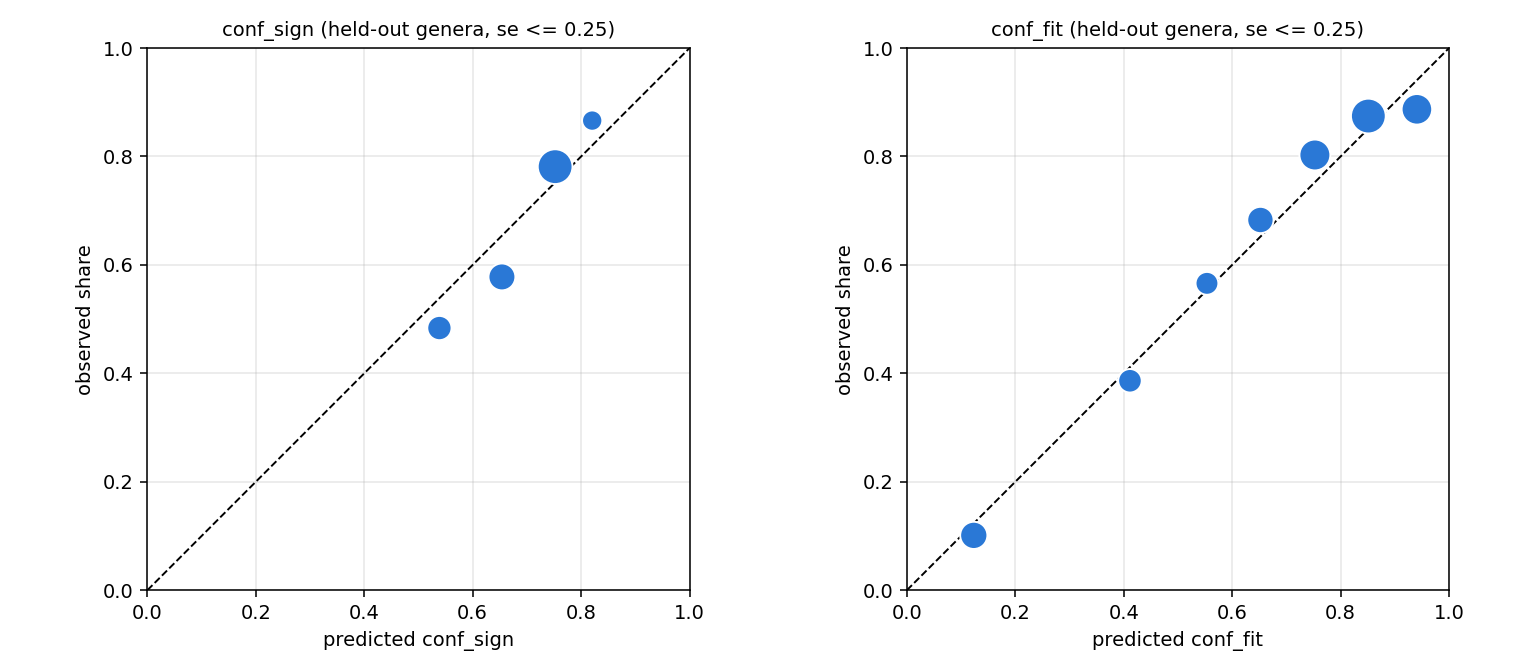

In [6]:
out = []
for genus in R.genus.unique():                                 # genus 하나씩 빼고 학습 -> 뺀 genus 에 적용
    tr, te = R[R.genus != genus], R[(R.genus == genus) & (R.se <= SE_MAX)]
    ps = np.maximum(0.5, expit(features(te.mu.values, te.sd.values, True) @ fit_sign(tr)))
    pf = expit(features(te.mu.values, te.sd.values, False) @ fit_fit(tr, DELTA, SE_MAX))
    out.append(pd.DataFrame({'conf_sign': ps, 'sign_hit': np.sign(te.y) == np.sign(te.mu),
                             'conf_fit': pf, 'fit_hit': np.abs(te.y - te.mu) <= DELTA}))
O = pd.concat(out, ignore_index=True)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.8))
for ax, (c, h) in zip(axes, (('conf_sign', 'sign_hit'), ('conf_fit', 'fit_hit'))):
    T = O.groupby(pd.cut(O[c], BINS, right=False), observed=True).agg(n=(h, 'size'), predicted=(c, 'mean'), observed=(h, 'mean'))
    T.index = T.index.astype(str)
    T.round(4).to_csv(f'{OUT_DIR}/check_{c}.csv', index_label='bin')
    print(f'held-out genus check - {c} (genes with se <= {SE_MAX})'); print(T.round(3).to_string(), '\n')
    ax.plot([0, 1], [0, 1], 'k--', lw=1)
    ax.scatter(T.predicted, T.observed, s=20 + 300 * T.n / T.n.max(), color='#2a78d6', edgecolor='white', zorder=3)
    ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.set_aspect('equal'); ax.grid(alpha=.3)
    ax.set_xlabel(f'predicted {c}'); ax.set_ylabel('observed share'); ax.set_title(f'{c} (held-out genera, se <= {SE_MAX})', fontsize=10)
fig.tight_layout(); fig.savefig(f'{OUT_DIR}/calibration.png', dpi=140); plt.close(fig)

## 6. 최종 계수

전체 예측으로 두 함수를 다시 학습해 `calibration.json` 에 저장한다. 서비스는 이 파일을 `assets/` 에 복사해 예측마다 $\mu$ · $\sigma$ 로 두 확률을 계산한다.

| 키 | 내용 |
|---|---|
| `sign` | `conf_sign` 계수 $\mathbf{w}$ — $(1, L, S, L S)$ 순 |
| `fit` | `conf_fit` 계수 $\mathbf{v}$ — $(1, L, S)$ 순 |
| `delta` · `se_max` | 허용 오차 · `conf_fit` 학습의 측정 오차 상한 |
| `source` · `n_predictions` | 보정 자료 |

효과가 크다고 예측된 유전자일수록 방향은 확실하지만(`conf_sign` 높음) 크기는 맞히기 어렵다(`conf_fit` 낮음).

In [7]:
cal = dict(sign=fit_sign(R).round(6).tolist(), fit=fit_fit(R, DELTA, SE_MAX).round(6).tolist(),
           delta=DELTA, se_max=SE_MAX, source='fitpred_ablation/noseq', n_predictions=int(len(R)))
with open(f'{OUT_DIR}/calibration.json', 'w', encoding='utf-8') as f:
    json.dump(cal, f, indent=1)
print('conf_sign weights (1, L, S, L*S):', cal['sign'])
print('conf_fit  weights (1, L, S):     ', cal['fit'])

# 예시 - 예측 평균 · 표준편차별 두 확률
ex = pd.DataFrame({'mu': [0.1, -0.5, -1.0, -2.0, -4.0, 1.0], 'sd': [0.5, 0.5, 0.5, 0.6, 1.0, 0.4]})
ex['conf_sign'] = np.maximum(0.5, expit(features(ex.mu, ex.sd, True) @ np.array(cal['sign'])))
ex['conf_fit']  = expit(features(ex.mu, ex.sd, False) @ np.array(cal['fit']))
print(ex.round(2).to_string(index=False))
print(f'\nsaved {OUT_DIR}/calibration.json | check_conf_sign.csv | check_conf_fit.csv | calibration.png')

conf_sign weights (1, L, S, L*S): [0.318034, 0.5716, -1.243491, 0.326997]
conf_fit  weights (1, L, S):      [-1.774267, -1.455614, -2.287381]
  mu  sd  conf_sign  conf_fit
 0.1 0.5       0.63      0.93
-0.5 0.5       0.73      0.66
-1.0 0.5       0.77      0.44
-2.0 0.6       0.78      0.16
-4.0 1.0       0.75      0.02
 1.0 0.4       0.81      0.56

saved ../results/calib_logistic/calibration.json | check_conf_sign.csv | check_conf_fit.csv | calibration.png
